Saved: c:\Users\vishw\OneDrive\เอกสาร\Presentable data for paper 1\Final_data\Multi_stage refinement heuristic\TEBD_Plots\laplacian_fidelity_4panel.pdf


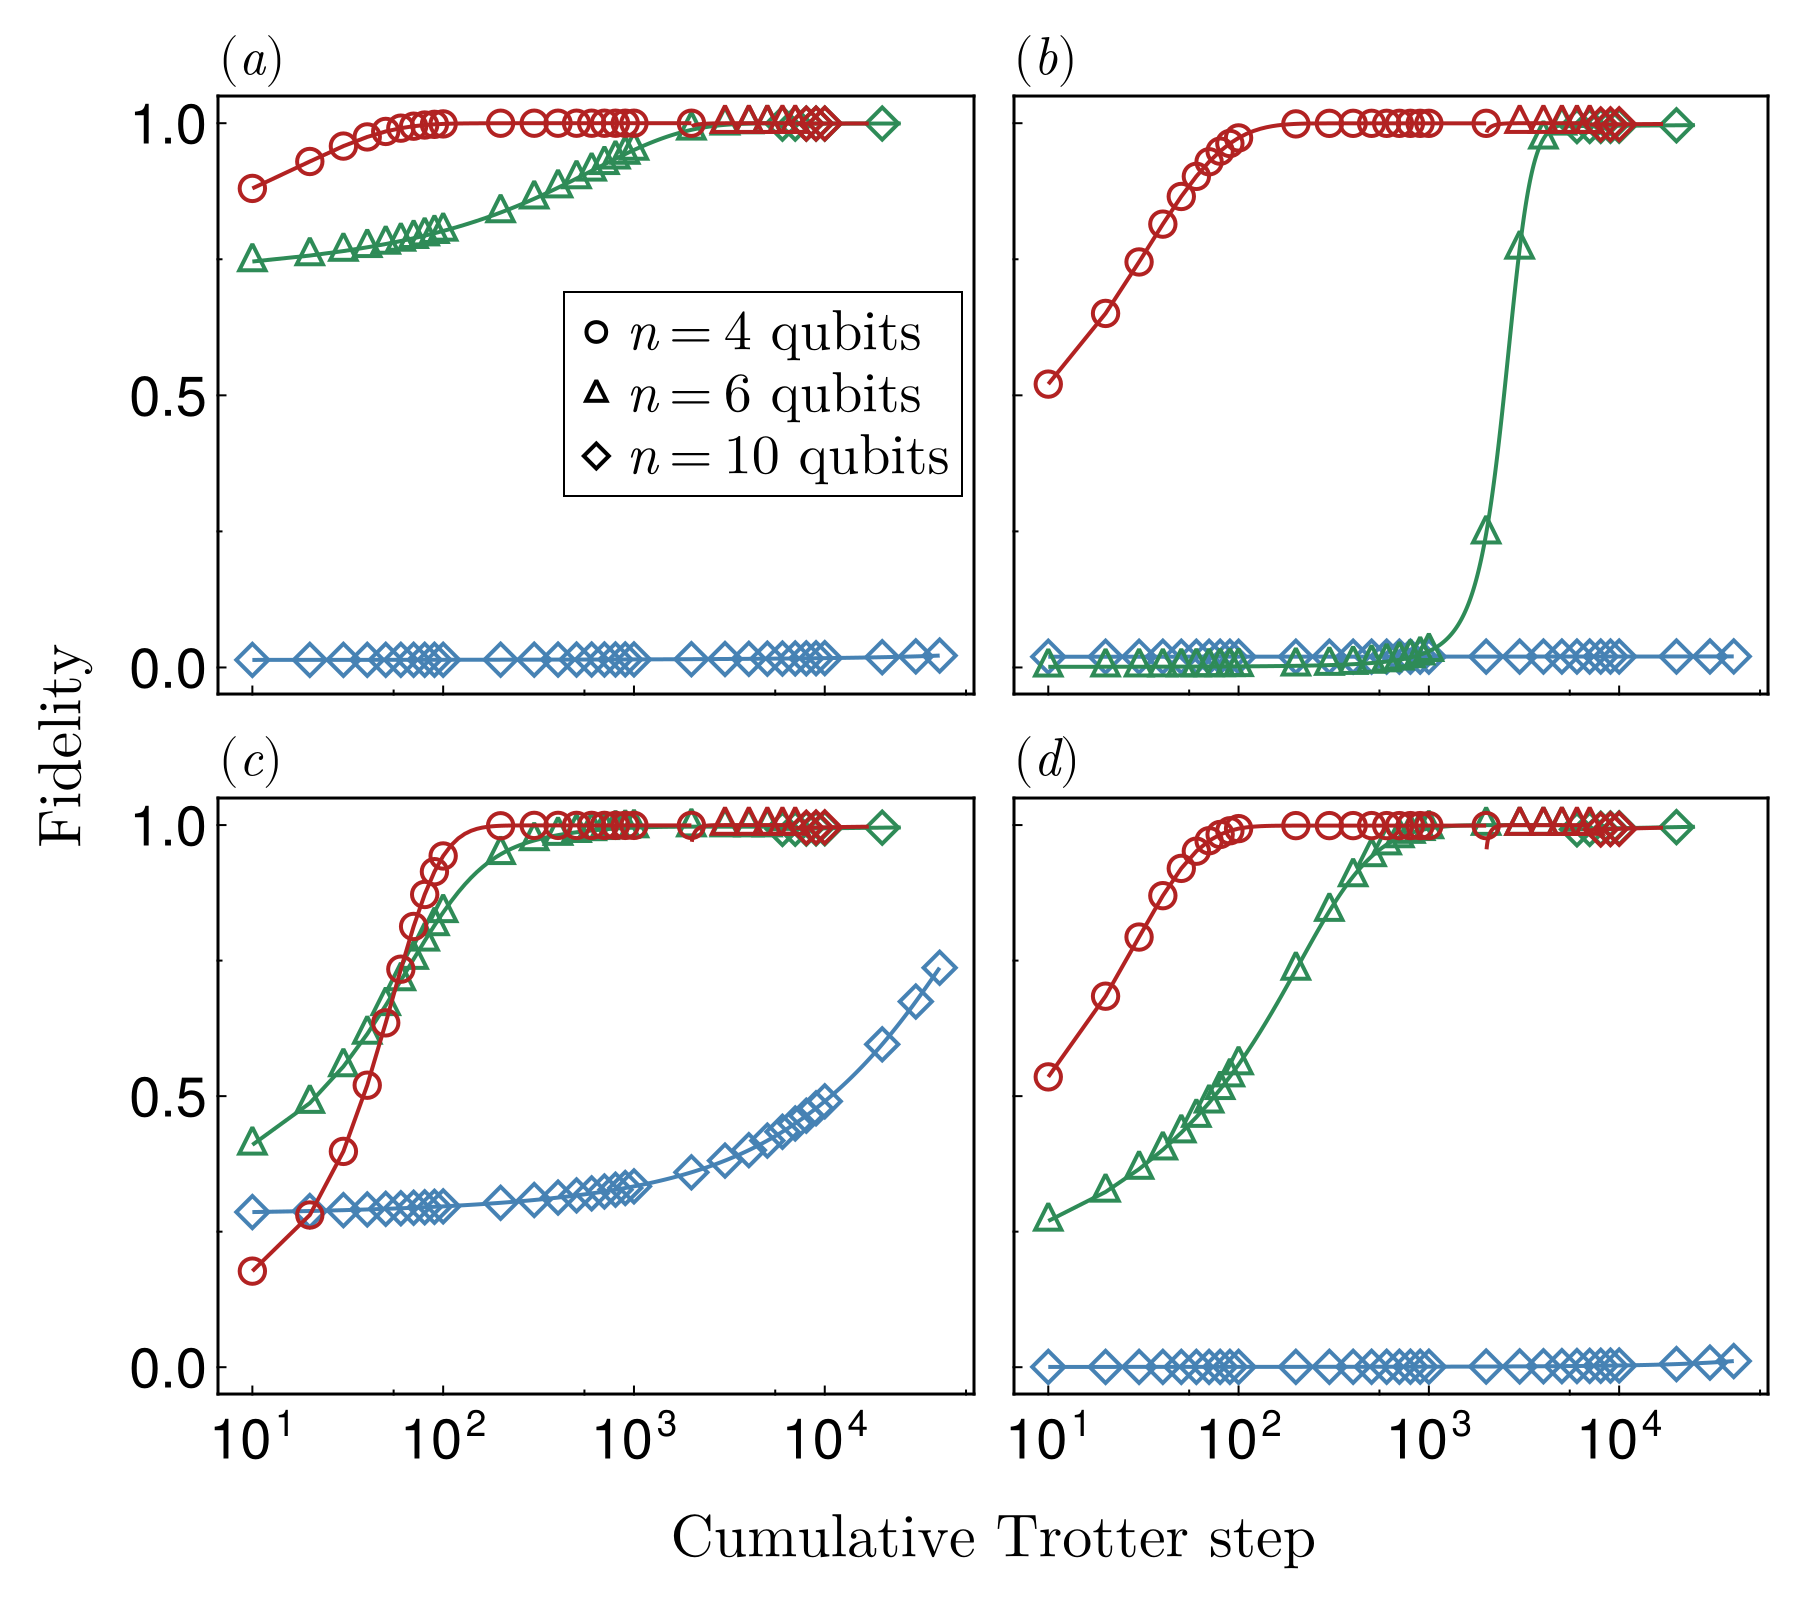

In [8]:
using JLD2, CairoMakie

infile = joinpath(@__DIR__, "tebd_results.jld2")
@load infile all_results strategies strategy_step_params operator_names num_states_by_operator CHECKPOINT_INTERVAL CHIMAX CUTOFF

const OP_NAME = "Laplacian"
const OUTDIR  = joinpath(@__DIR__, "TEBD_Plots")
isdir(OUTDIR) || mkpath(OUTDIR)

num_states = num_states_by_operator[OP_NAME]
op_results = all_results[OP_NAME]

strategy_names = collect(keys(strategies))
sort!(strategy_names, by = s -> length(strategies[s]))

STRATEGY_COLORS = Dict(
    strategy_names[1] => :steelblue,
    strategy_names[2] => :seagreen,
    strategy_names[3] => :firebrick,
)

all_Ns = sort(unique(vcat(values(strategies)...)))
N_MARKERS = Dict(
    all_Ns[1] => :circle,
    all_Ns[2] => :utriangle,
    all_Ns[3] => :diamond,
)

function adaptive_mask(steps::Vector{Int})
    keep = falses(length(steps))
    for (i, s) in enumerate(steps)
        if s <= 100
            keep[i] = (s % 10 == 0)
        elseif s <= 1000
            keep[i] = (s % 100 == 0)
        elseif s <= 10000
            keep[i] = (s % 1000 == 0)
        else
            keep[i] = (s % 10000 == 0)
        end
    end
    return keep
end

set_theme!(Theme(
    fontsize = 11,
    Axis = (
        xlabelsize = 30, ylabelsize = 30,
        xticklabelsize = 28, yticklabelsize = 28,
        xgridvisible = false, ygridvisible = false,
        xtickalign = 1, ytickalign = 1,
        xminorticksvisible = true, yminorticksvisible = true,
        xminortickalign = 1, yminortickalign = 1,
        spinewidth = 1.5,
        backgroundcolor = :white,
        xscale = log10,
    ),
))

function draw_panel!(ax, state_idx::Int)
    for strat in strategy_names
        stage_Ns = strategies[strat]
        color    = STRATEGY_COLORS[strat]
        offset   = 0
        for N in stage_Ns
            res   = op_results[strat][N]
            steps = res.steps[state_idx] .+ offset
            yvals = res.fidelity[state_idx]

            lines!(ax, steps, yvals; color = color, linewidth = 2.0)

            mask = adaptive_mask(steps)
            scatter!(ax, steps[mask], yvals[mask];
                      marker = N_MARKERS[N],
                      markersize = 18,
                      color = :transparent,
                      strokecolor = color,
                      strokewidth = 2.0)

            offset += res.K
        end
    end
end

fig = Figure(size = (900, 800), backgroundcolor = :white)

panel_labels = [L"(a)", L"(b)", L"(c)", L"(d)"]
grid_pos     = [(1,1), (1,2), (2,1), (2,2)]

axes_grid = Dict{Tuple{Int,Int},Axis}()

for (state_idx, pos) in zip(1:num_states, grid_pos)
    row, col = pos
    ax = Axis(fig[row, col], backgroundcolor = :white)
    draw_panel!(ax, state_idx)
    axes_grid[pos] = ax

    # panel label, outside the axis, top-left (like a left-aligned title)
    Label(fig[row, col, Top()], panel_labels[state_idx],
          fontsize = 26, font = :bold, halign = :left, padding = (0, 0, 5, 0))
end

# --- link axes: columns share x, rows share y ---
linkxaxes!(axes_grid[(1,1)], axes_grid[(2,1)])   # column 1: a,c
linkxaxes!(axes_grid[(1,2)], axes_grid[(2,2)])   # column 2: b,d
linkyaxes!(axes_grid[(1,1)], axes_grid[(1,2)])   # row 1: a,b
linkyaxes!(axes_grid[(2,1)], axes_grid[(2,2)])   # row 2: c,d

hidexdecorations!(axes_grid[(1,1)], grid = false, minorgrid = false, ticks = false, minorticks = false)
hidexdecorations!(axes_grid[(1,2)], grid = false, minorgrid = false, ticks = false, minorticks = false)
hideydecorations!(axes_grid[(1,2)], grid = false, minorgrid = false, ticks = false, minorticks = false)
hideydecorations!(axes_grid[(2,2)], grid = false, minorgrid = false, ticks = false, minorticks = false)

# --- shared axis labels (outside the grid) ---
Label(fig[3, 1:2], L"Cumulative Trotter step$$", fontsize = 30)
Label(fig[1:2, 0], L"Fidelity$$", fontsize = 30, rotation = pi/2)

rowgap!(fig.layout, 20)
colgap!(fig.layout, 20)

# legend inside panel (a) only
leg_elems  = [MarkerElement(marker = N_MARKERS[N], color = :transparent,
                             strokecolor = :black, strokewidth = 2.0,
                             markersize = 14) for N in all_Ns]
leg_labels = [L"n = %$(N)\ \text{qubits}" for N in all_Ns]
axislegend(axes_grid[(1,1)], leg_elems, leg_labels,
           position = :rc, framevisible = true, labelsize = 28)

outfile = joinpath(OUTDIR, "laplacian_fidelity_4panel.pdf")
save(outfile, fig)
println("Saved: ", outfile)
fig